<a href="https://colab.research.google.com/github/annagiacometti/multimodal-domestic-scene-extraction/blob/main/multimodal_domestic_scene_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estrazione Strutturata di Metadati Visivi in Ambienti Domestici tramite Vision-Language Models (VLM)

**Autrice:** Anna Giacometti  
**Obiettivo:** Esperimento riproducibile di inferenza con un modello multimodale open source (*Qwen/Qwen2.5-VL-3B-Instruct*) per trasformare immagini non strutturate di ambienti domestici e attività quotidiane in schede JSON strutturate.

### Metodologia e Strumenti
* **Modello VLM:** `Qwen/Qwen2.5-VL-3B-Instruct` eseguito su acceleratore GPU (Google Colab T4) tramite la libreria Hugging Face `transformers`.
* **Dataset:** Campione filtrato in streaming dal dataset aperto `lmms-lab/COCO-Caption` (split `val`).
* **Output:** Estrazione controllata tramite prompt strutturato in formato JSON (`contesto_stanza`, `oggetti_principali`, `attivita_rilevata`, `stato_ambiente`, `suggerimento_supporto`) e confronto qualitativo con le didascalie umane di riferimento (*ground truth*).

## 1. Configurazione dell'ambiente e installazione delle librerie
Installazione dei pacchetti necessari per l'esecuzione del modello multimodale (`transformers`, `accelerate`, `qwen-vl-utils`, `torch`), la gestione dei dataset in streaming (`datasets`, `pillow`) e l'esportazione tabellare (`pandas`).

In [3]:
!pip install -q transformers accelerate datasets pillow qwen-vl-utils torch pandas

## 2. Caricamento del modello Vision-Language (`Qwen2.5-VL-3B-Instruct`)
Inizializzazione del modello pre-addestrato e del relativo `AutoProcessor` in precisione ridotta (`float16`) con allocazione automatica sulla GPU disponibile.

In [1]:
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(model_id)
print("Modello caricato correttamente su:", model.device)

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Modello caricato correttamente su: cuda:0


## 3. Campionamento in streaming dal dataset aperto COCO
Accesso in modalità `streaming=True` al dataset `lmms-lab/COCO-Caption` per selezionare un campione di 5 immagini inerenti ad ambienti interni domestici e oggetti di uso quotidiano, visualizzando un primo esempio con la relativa didascalia di riferimento (*ground truth*).

Raccolti 50 campioni di ambienti/oggetti domestici.


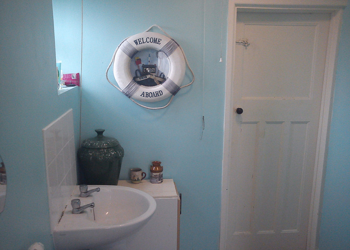

Descrizione originale (Ground Truth): A room with blue walls and a white sink and door.


In [6]:
from datasets import load_dataset

# Caricamento in streaming dal dataset open COCO in formato Parquet
dataset = load_dataset("lmms-lab/COCO-Caption", split="val", streaming=True)

parole_chiave_casa = {"kitchen", "living room", "bedroom", "table", "couch", "chair", "sink", "cup", "bowl", "book"}
sample_items = []

for item in dataset:
    caption = item["answer"][0].lower()
    if any(parola in caption for parola in parole_chiave_casa):
        sample_items.append(item)
    if len(sample_items) == 50:
        break

print(f"Raccolti {len(sample_items)} campioni di ambienti/oggetti domestici.")

# Visualizza il primo campione estratto
display(sample_items[0]["image"].resize((350, 250)))
print("Descrizione originale (Ground Truth):", sample_items[0]["answer"][0])

## 4. Pipeline di inferenza multimodale ed estrazione metadati in JSON
Definizione dello schema di estrazione tramite prompt testuale ed esecuzione dell'inferenza su ciascuna immagine del campione per generare una descrizione strutturata dell'ambiente, degli oggetti rilevati, dell'attività in corso e di un eventuale supporto pratico.

In [7]:
import pandas as pd

prompt_domestico = """
Analizza l'immagine di questo ambiente o attività quotidiana e restituisci esclusivamente un oggetto JSON valido con i seguenti campi:
- "contesto_stanza": tipo di ambiente domestico o contesto (es. cucina, soggiorno, studio, altro)
- "oggetti_principali": lista di massimo 5 oggetti rilevati nella scena
- "attivita_rilevata": breve descrizione dell'attività o situazione osservata
- "stato_ambiente": valutazione sintetica (es. ordinato, in uso, disordinato)
- "suggerimento_supporto": una breve azione pratica di supporto utile all'utente in questo contesto
"""

results = []

for idx, item in enumerate(sample_items):
    image = item["image"].convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt_domestico},
            ],
        }
    ]

    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        generated_ids = model.generate(**inputs, max_new_tokens=256, do_sample=False)

    generated_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]

    results.append({
        "id_campione": idx,
        "caption_ground_truth": item["answer"][0],
        "json_estratto_vlm": output_text
    })
    if (idx + 1) % 10 == 0:
        print(f"Elaborate {idx + 1}/{len(sample_items)} immagini...")

df_risultati = pd.DataFrame(results)

for _, row in df_risultati.iterrows():
    print(f"=== Campione {row['id_campione']} ===")
    print("Riferimento umano:", row["caption_ground_truth"])
    print("Output VLM:\n", row["json_estratto_vlm"], "\n")

Elaborate 10/50 immagini...
Elaborate 20/50 immagini...
Elaborate 30/50 immagini...
Elaborate 40/50 immagini...
Elaborate 50/50 immagini...
=== Campione 0 ===
Riferimento umano: A room with blue walls and a white sink and door.
Output VLM:
 ```json
{
  "contesto_stanza": "bagno",
  "oggetti_principali": [
    "coperchio del vaso da bagno",
    "candela",
    "coppa",
    "lavabo con rubinetto",
    "portello"
  ],
  "attivita_rilevata": "nessuna attività specifica",
  "stato_ambiente": "ordinato",
  "suggerimento_supporto": "Verificare se ci sono eventuali residui di sapone o altri detriti sul lavabo prima di usare il bagno."
}
``` 

=== Campione 1 ===
Riferimento umano: A bathroom with a toilet, sink, and shower.
Output VLM:
 ```json
{
  "contesto_stanza": "bagno",
  "oggetti_principali": [
    " WC",
    " lavandino",
    " specchio",
    " tenda",
    " asciugamano"
  ],
  "attivita_rilevata": "riposo o preparazione per il bagno",
  "stato_ambiente": "ordinato",
  "suggerimento_supp

In [8]:
import json

json_validi = 0
for r in results:
    testo_pulito = r["json_estratto_vlm"].replace("```json", "").replace("```", "").strip()
    try:
        json.loads(testo_pulito)
        json_validi += 1
    except json.JSONDecodeError:
        pass

print(f"Validità sintattica JSON: {json_validi}/{len(results)} ({json_validi/len(results)*100:.0f}%)")

Validità sintattica JSON: 50/50 (100%)


## 5. Esportazione dei risultati
Salvataggio della tabella comparativa (ID campione, didascalia di riferimento e output JSON generato dal modello) in formato `.csv` per la consultazione e l'analisi qualitativa degli errori.

In [9]:
df_risultati.to_csv("domestic_scene_vlm_results.csv", index=False)
print("File esportato: domestic_scene_vlm_results.csv")

File esportato: domestic_scene_vlm_results.csv


## 6. Validazione sintattica e confronto qualitativo con le annotazioni COCO
Verifica automatica della validità sintattica degli output JSON tramite parsing (`json.loads`) e confronto lessicale tra le categorie estratte dal modello (in italiano) e le didascalie umane di riferimento del dataset COCO (in inglese), seguito dall'ispezione manuale di un sottoinsieme di campioni.

In [10]:
import json
import pandas as pd

# Dizionario minimo IT -> EN per confrontare i termini del VLM con le caption COCO in inglese
mappa_termini = {
    "cucina": ["kitchen"],
    "soggiorno": ["living room", "couch", "sofa"],
    "camera": ["bedroom", "bed"],
    "bagno": ["bathroom", "toilet", "sink"],
    "studio": ["office", "desk", "computer", "laptop"],
    "tavolo": ["table", "desk"],
    "sedia": ["chair"],
    "divano": ["couch", "sofa"],
    "tazza": ["cup", "mug"],
    "ciotola": ["bowl"],
    "libro": ["book"],
    "fornello": ["stove", "oven"],
    "frigorifero": ["refrigerator", "fridge"],
    "lavandino": ["sink"],
    "piatto": ["plate", "dish"],
    "persona": ["person", "man", "woman", "boy", "girl", "people"],
    "cane": ["dog"],
    "gatto": ["cat"]
}

analisi = []
match_almeno_un_elemento = 0

for _, row in df_risultati.iterrows():
    gt = row["caption_ground_truth"].lower()
    raw_json = row["json_estratto_vlm"].replace("```json", "").replace("```", "").strip()
    data = json.loads(raw_json)

    stanza = str(data.get("contesto_stanza", "")).lower()
    oggetti = [str(o).lower() for o in data.get("oggetti_principali", [])]
    testo_vlm_it = stanza + " " + " ".join(oggetti)

    # Verifica se almeno un concetto rilevato dal modello trova riscontro nella caption COCO
    trovato = False
    concetti_confermati = []
    for it_word, en_list in mappa_termini.items():
        if it_word in testo_vlm_it and any(en_w in gt for en_w in en_list):
            trovato = True
            concetti_confermati.append(it_word)

    if trovato:
        match_almeno_un_elemento += 1

    analisi.append({
        "ID": row["id_campione"],
        "Ground Truth (COCO)": row["caption_ground_truth"],
        "Stanza VLM": data.get("contesto_stanza"),
        "Oggetti VLM": ", ".join(data.get("oggetti_principali", [])),
        "Attività VLM": data.get("attivita_rilevata"),
        "Riscontro diretto nella GT": ", ".join(concetti_confermati) if concetti_confermati else "Nessuno (dettagli complementari o contesto esterno)"
    })

df_confronto = pd.DataFrame(analisi)
print(f"Campioni con riscontro lessicale diretto nella didascalia COCO: {match_almeno_un_elemento}/{len(df_confronto)} ({match_almeno_un_elemento/len(df_confronto)*100:.0f}%)\n")

# Stampa i primi 10 confronti per ispezione qualitativa
for _, r in df_confronto.head(10).iterrows():
    print(f"[{r['ID']}] COCO: {r['Ground Truth (COCO)']}")
    print(f"     VLM -> Stanza: {r['Stanza VLM']} | Oggetti: {r['Oggetti VLM']} | Attività: {r['Attività VLM']}")
    print(f"     Conferma: {r['Riscontro diretto nella GT']}\n")

Campioni con riscontro lessicale diretto nella didascalia COCO: 45/50 (90%)

[0] COCO: A room with blue walls and a white sink and door.
     VLM -> Stanza: bagno | Oggetti: coperchio del vaso da bagno, candela, coppa, lavabo con rubinetto, portello | Attività: nessuna attività specifica
     Conferma: bagno

[1] COCO: A bathroom with a toilet, sink, and shower.
     VLM -> Stanza: bagno | Oggetti:  WC,  lavandino,  specchio,  tenda,  asciugamano | Attività: riposo o preparazione per il bagno
     Conferma: bagno, lavandino

[2] COCO: A long empty, minimal modern skylit home kitchen.
     VLM -> Stanza: cucina | Oggetti: frigorifero, cucina, ovatta, lavastoviglie, cucina | Attività: la cucina è pronta per essere utilizzata
     Conferma: cucina

[3] COCO: A bathroom sink with toiletries on the counter.
     VLM -> Stanza: bagno | Oggetti: cassettiera nera, cucchiaino, cucchiaino, cucchiaino, cucchiaino | Attività: riposo o preparazione per il bagno
     Conferma: bagno

[4] COCO: A gas

## 7. Osservazioni conclusive e limiti dell'esperimento
* **Validità strutturale (100% – 50/50):** L'impiego di un prompt vincolato a uno schema predefinito, unito alla decodifica deterministica (`do_sample=False`), ha garantito la generazione di oggetti JSON sintatticamente validi su tutti e 50 i campioni elaborati.
* **Coerenza semantica (90% – 45/50):** Nel 90% dei casi gli elementi principali rilevati dal modello trovano riscontro diretto nelle didascalie umane di riferimento di COCO, con particolare precisione nel riconoscimento di ambienti domestici chiari (es. cucina, bagno).
* **Nota multilingue e limiti osservati:** L'utilizzo di un prompt in italiano su immagini annotate in inglese ha permesso di osservare il comportamento multilingue *zero-shot* di `Qwen2.5-VL-3B-Instruct`. L'ispezione manuale evidenzia tuttavia alcuni limiti tipici dei modelli compatti (3B parametri):
  * **Ripetizione lessicale:** Tendenza occasionale a ripetere voci identiche all'interno della lista `oggetti_principali` (es. ripetizione dello stesso termine nella medesima scheda).
  * **Imprecisioni su dettagli secondari e *code-switching*:** Sporadiche attribuzioni errate su oggetti di piccole dimensioni in scene affollate o passaggio all'inglese in corrispondenza di scene esterne entrate nel campione per ambiguità delle parole chiave di filtro.